**Assignment 1 – Heart Disease (Cleveland Database)**

Group9: Hatice AY, Bedia Nur ELMAS, Mahyar Naeimi

The file processed.cleveland.data must be in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "processed.cleveland.data"       # relative path to the provided dataset
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS, na_values="?")   # "?" = missing value
print(df.shape)

(303, 14)


**Pipeline and models**

Same pre-processing and classifiers as in Task 2 and 3.

In [2]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42

features = [c for c in df.columns if c != "num"]
X = df[features]
y_multi = df["num"].values

NOMINAL = ["cp", "restecg", "slope", "thal"]      # labels, not real numbers -> one-hot
OTHER = [c for c in features if c not in NOMINAL]

def make_preprocessor():
    nominal = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    other = Pipeline([("impute", SimpleImputer(strategy="most_frequent"))])
    return Pipeline([("columns", ColumnTransformer([("nom", nominal, NOMINAL),
                                                    ("oth", other, OTHER)])),
                     ("scale", StandardScaler())])

def make_models():
    return {
        "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "kNN (k=15)": KNeighborsClassifier(n_neighbors=15),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
        "SVM (RBF)": SVC(kernel="rbf", random_state=RANDOM_STATE),
    }

def pipe(model):
    # preprocessing is fitted on the training folds only -> no data leakage
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

**Task 4 – ROC curves for the 2-class problem**

For each classifier we compute a score for "disease" for every patient with 5-fold cross-validation (each patient is scored by a model that did not see it). For Logistic Regression, kNN and Random Forest this is the predicted probability, for the SVM it is the distance to the decision boundary. The ROC curve shows the sensitivity against 1 − specificity for all possible thresholds, and the AUC is the area under the curve.

Logistic Regression at threshold 0.5: sensitivity = 0.79, specificity = 0.89


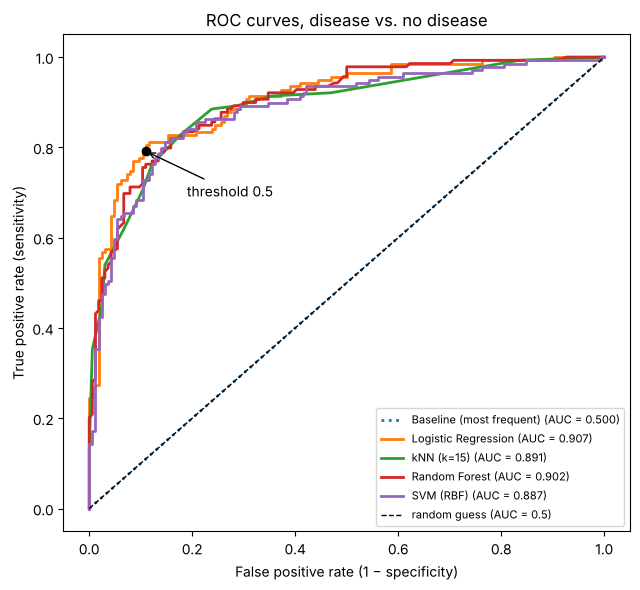

In [3]:
from sklearn.metrics import roc_curve, auc

y_bin = (df["num"] > 0).astype(int).values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(6.5, 6))
for name, model in make_models().items():
    if hasattr(model, "predict_proba"):
        score = cross_val_predict(pipe(model), X, y_bin, cv=cv, method="predict_proba")[:, 1]
        default_threshold = 0.5
    else:   # SVM: distance to the decision boundary, default threshold 0
        score = cross_val_predict(pipe(model), X, y_bin, cv=cv, method="decision_function")
        default_threshold = 0.0
    fpr, tpr, thr = roc_curve(y_bin, score)
    style = ":" if name.startswith("Baseline") else "-"
    ax.plot(fpr, tpr, style, lw=2, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
    if name == "Logistic Regression":
        i = np.argmin(np.abs(thr - default_threshold))   # point of the default threshold 0.5
        ax.plot(fpr[i], tpr[i], "ko")
        ax.annotate("threshold 0.5", (fpr[i], tpr[i]), xytext=(fpr[i] + 0.08, tpr[i] - 0.1),
                    arrowprops={"arrowstyle": "->"})
        print(f"Logistic Regression at threshold 0.5: sensitivity = {tpr[i]:.2f}, "
              f"specificity = {1 - fpr[i]:.2f}")

ax.plot([0, 1], [0, 1], "k--", lw=1, label="random guess (AUC = 0.5)")
ax.set(xlabel="False positive rate (1 − specificity)", ylabel="True positive rate (sensitivity)",
       title="ROC curves, disease vs. no disease")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation**

All four classifiers are far above the diagonal, which stands for random guessing (AUC = 0.5). The baseline lies exactly on the diagonal because it gives every patient the same score.

The AUC is about 0.89 to 0.91 for all models. This means: if we pick one random diseased and one random healthy patient, the model gives the diseased patient the higher score in about 90 % of the cases. The curves cross each other and the differences are very small, so no model is clearly better. The simple Logistic Regression is as good as the more complex Random Forest and SVM.

The ROC curve also shows the trade-off between sensitivity and specificity. With the default threshold 0.5 (black point) Logistic Regression finds about 79 % of the diseased patients with a specificity of about 89 %. For screening, where a missed disease is worse than a false alarm, we would lower the threshold and move to the right on the curve: for example, a sensitivity of about 0.9 is possible with a specificity of about 0.7.